This project uses Machine Learning for Employee Performance and HR Analytics. Random Forest Regression was used to predict employee training performance scores, while K-Means Clustering was used to group employees based on their work-related characteristics. Feature importance helped identify the factors contributing to the prediction. The project demonstrates how supervised and unsupervised learning can be combined to analyze employee data and support data-driven HR decisions.



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile
import os

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving archive (4).zip to archive (4) (1).zip


In [ ]:
zip_file = "archive (4).zip"

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall("hr_dataset")

print("ZIP extracted successfully!")

ZIP extracted successfully!


In [ ]:
os.listdir("hr_dataset")

['Uncleaned_employees_final_dataset (1).csv']

In [ ]:
file_path = "hr_dataset/Uncleaned_employees_final_dataset (1).csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 17417
Columns: 13


In [ ]:
df.head()


,employee_id,department,region,education,gender,recruitment_channel,no_of_trainings,age,previous_year_rating,length_of_service,KPIs_met_more_than_80,awards_won,avg_training_score
0,8724,Technology,region_26,Bachelors,m,sourcing,1,24,NaN,1,1,0,77
1,74430,HR,region_4,Bachelors,f,other,1,31,3.0,5,0,0,51
2,72255,Sales & Marketing,region_13,Bachelors,m,other,1,31,1.0,4,0,0,47
3,38562,Procurement,region_2,Bachelors,f,other,3,31,2.0,9,0,0,65
4,64486,Finance,region_29,Bachelors,m,sourcing,1,30,4.0,7,0,0,61


In [ ]:
print(df.columns.tolist())

['employee_id', 'department', 'region', 'education', 'gender', 'recruitment_channel', 'no_of_trainings', 'age', 'previous_year_rating', 'length_of_service', 'KPIs_met_more_than_80', 'awards_won', 'avg_training_score']


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17417 entries, 0 to 17416
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   employee_id            17417 non-null  int64  
 1   department             17417 non-null  object 
 2   region                 17417 non-null  object 
 3   education              16646 non-null  object 
 4   gender                 17417 non-null  object 
 5   recruitment_channel    17417 non-null  object 
 6   no_of_trainings        17417 non-null  int64  
 7   age                    17417 non-null  int64  
 8   previous_year_rating   16054 non-null  float64
 9   length_of_service      17417 non-null  int64  
 10  KPIs_met_more_than_80  17417 non-null  int64  
 11  awards_won             17417 non-null  int64  
 12  avg_training_score     17417 non-null  int64  
dtypes: float64(1), int64(7), object(5)
memory usage: 1.7+ MB


In [ ]:
df.isnull().sum()

,0
employee_id,0
department,0
region,0
education,771
gender,0
recruitment_channel,0
no_of_trainings,0
age,0
previous_year_rating,1363
length_of_service,0


In [ ]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage)

employee_id              0.000000
department               0.000000
region                   0.000000
education                4.426710
gender                   0.000000
recruitment_channel      0.000000
no_of_trainings          0.000000
age                      0.000000
previous_year_rating     7.825688
length_of_service        0.000000
KPIs_met_more_than_80    0.000000
awards_won               0.000000
avg_training_score       0.000000
dtype: float64


In [ ]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 2


In [ ]:
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (17415, 13)


In [ ]:
df.describe()

,employee_id,no_of_trainings,age,previous_year_rating,length_of_service,KPIs_met_more_than_80,awards_won,avg_training_score
count,17415.000000,17415.000000,17415.000000,16052.000000,17415.000000,17415.000000,17415.000000,17415.000000
mean,39082.285214,1.250761,34.807982,3.345751,5.801493,0.358886,0.023371,63.177720
std,22708.049139,0.595720,7.694464,1.265194,4.175632,0.479687,0.151082,13.418314
min,3.000000,1.000000,20.000000,1.000000,1.000000,0.000000,0.000000,39.000000
25%,19280.500000,1.000000,29.000000,3.000000,3.000000,0.000000,0.000000,51.000000
50%,39115.000000,1.000000,33.000000,3.000000,5.000000,0.000000,0.000000,60.000000
75%,58838.500000,1.000000,39.000000,4.000000,7.000000,1.000000,0.000000,75.000000
max,78295.000000,9.000000,60.000000,5.000000,34.000000,1.000000,1.000000,99.000000


In [ ]:
categorical_columns = df.select_dtypes(include='object').columns

print("Categorical columns:")
print(categorical_columns.tolist())


Categorical columns:
['department', 'region', 'education', 'gender', 'recruitment_channel']


In [ ]:
for col in categorical_columns:
    print("\n", col)
    print(df[col].unique())


 department
['Technology' 'HR' 'Sales & Marketing' 'Procurement' 'Finance' 'Analytics'
 'Operations' 'Legal' 'R&D']

 region
['region_26' 'region_4' 'region_13' 'region_2' 'region_29' 'region_7'
 'region_22' 'region_16' 'region_17' 'region_24' 'region_11' 'region_27'
 'region_9' 'region_20' 'region_34' 'region_23' 'region_8' 'region_14'
 'region_31' 'region_19' 'region_5' 'region_28' 'region_15' 'region_3'
 'region_25' 'region_12' 'region_21' 'region_30' 'region_10' 'region_33'
 'region_32' 'region_6' 'region_1' 'region_18']

 education
['Bachelors' 'Masters & above' nan 'Below Secondary']

 gender
['m' 'f']

 recruitment_channel
['sourcing' 'other' 'referred']


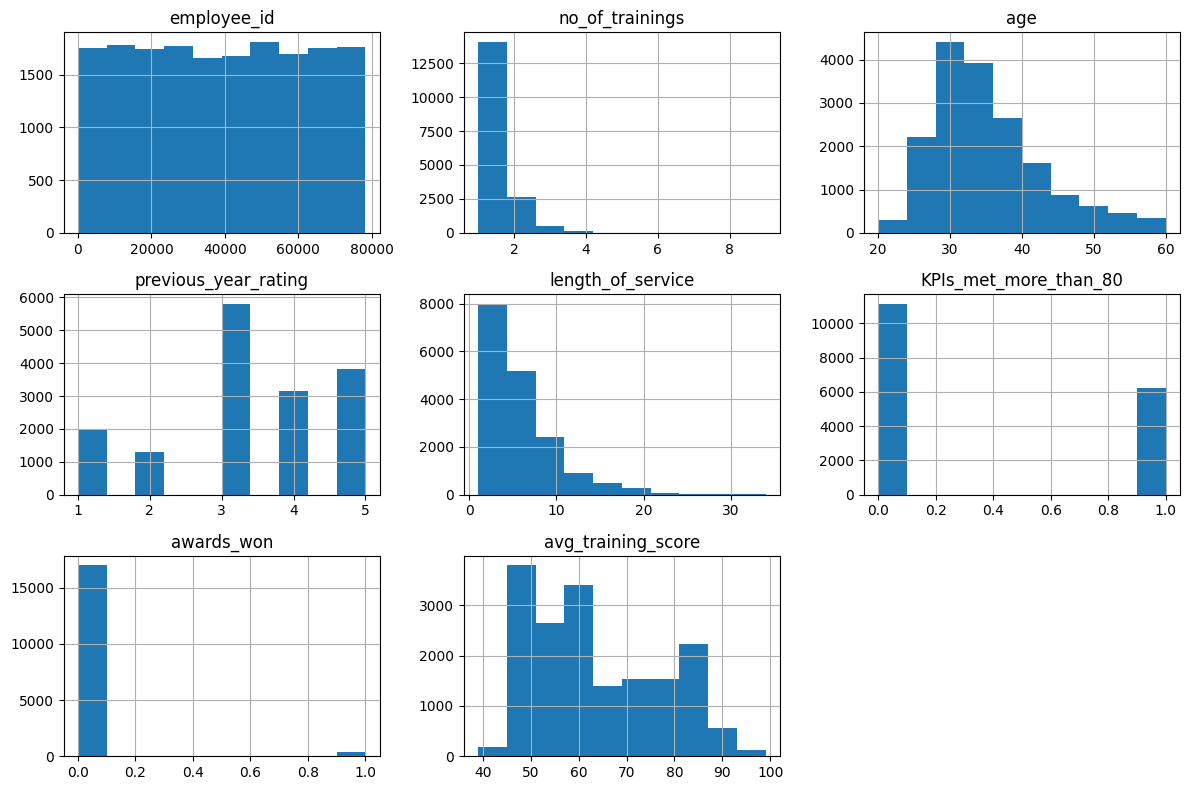

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

df.hist(figsize=(12,8))
plt.tight_layout()
plt.show()

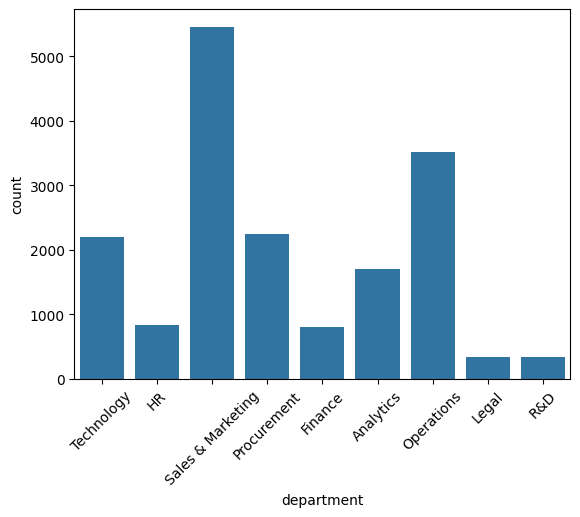

In [ ]:
sns.countplot(data=df, x="department")
plt.xticks(rotation=45)
plt.show()

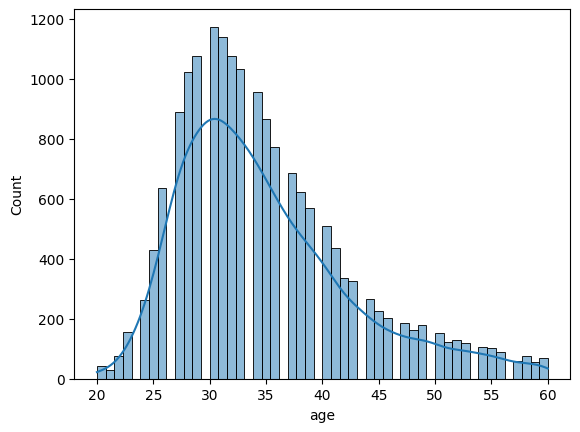

In [ ]:
sns.histplot(data=df, x="age", kde=True)
plt.show()

Correlation

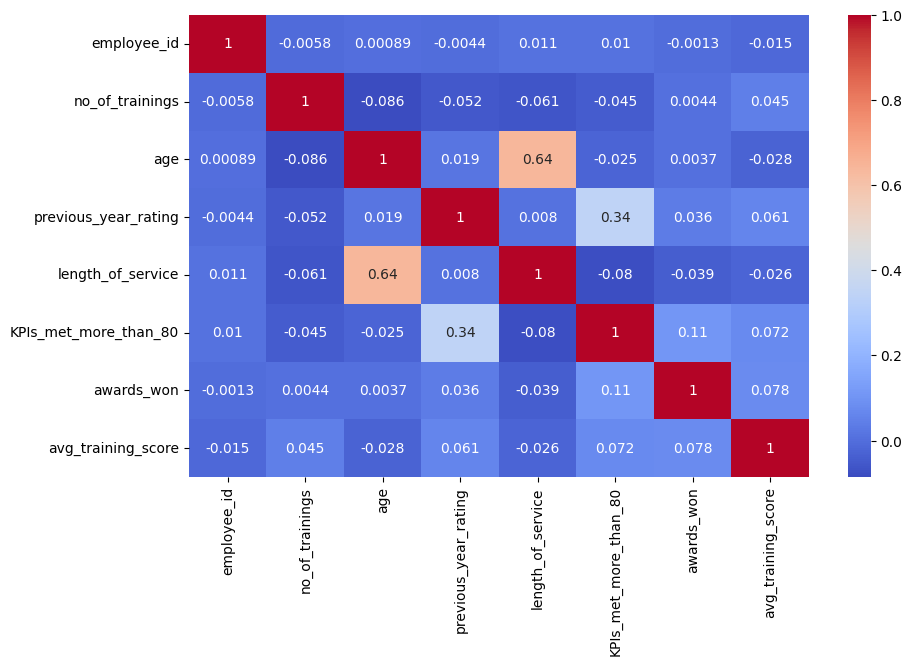

In [ ]:
corr = df.select_dtypes('number').corr()

plt.figure(figsize=(10,6))
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.show()

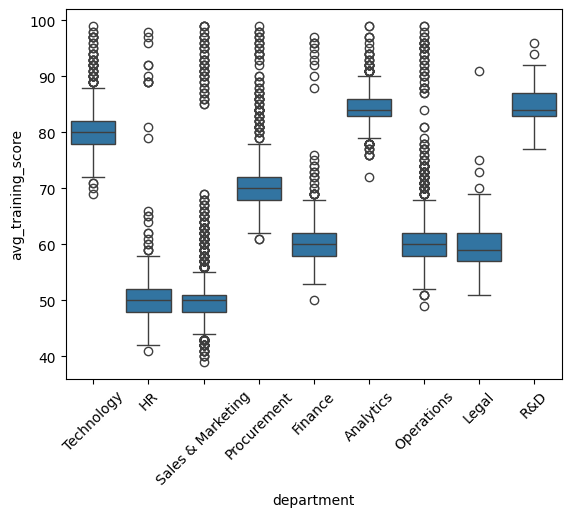

In [ ]:
sns.boxplot(data=df, x="department", y="avg_training_score")
plt.xticks(rotation=45)
plt.show()

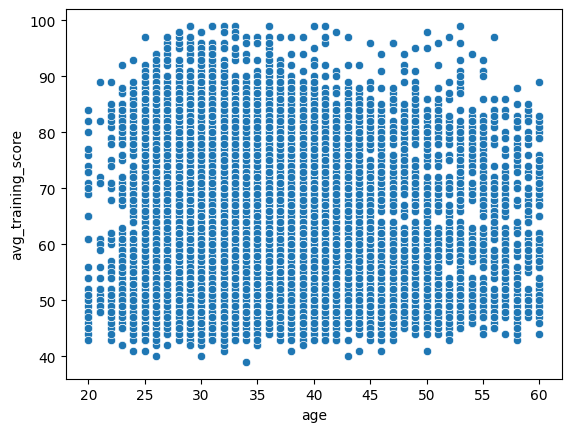

In [ ]:
sns.scatterplot(data=df, x="age", y="avg_training_score")
plt.show()

Data Preprocessing

In [ ]:
cat_cols = df.select_dtypes(include='object').columns
print(cat_cols)

Index(['department', 'region', 'education', 'gender', 'recruitment_channel'], dtype='object')


In [ ]:
df_encoded = pd.get_dummies(df, columns=cat_cols, drop_first=True)

In [ ]:
df_encoded.head()

,employee_id,no_of_trainings,age,previous_year_rating,length_of_service,KPIs_met_more_than_80,awards_won,avg_training_score,department_Finance,department_HR,...,region_region_6,region_region_7,region_region_8,region_region_9,education_Below Secondary,education_Masters & above,education_nan,gender_m,recruitment_channel_referred,recruitment_channel_sourcing
0,8724,1,24,NaN,1,1,0,77,False,False,...,False,False,False,False,False,False,False,True,False,True
1,74430,1,31,3.0,5,0,0,51,False,True,...,False,False,False,False,False,False,False,False,False,False
2,72255,1,31,1.0,4,0,0,47,False,False,...,False,False,False,False,False,False,False,True,False,False
3,38562,3,31,2.0,9,0,0,65,False,False,...,False,False,False,False,False,False,False,False,False,False
4,64486,1,30,4.0,7,0,0,61,True,False,...,False,False,False,False,False,False,False,True,False,True


Supervised Target

In [ ]:
X = df_encoded.drop("avg_training_score", axis=1)
y = df_encoded["avg_training_score"]

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

Random Forest Regression

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

In [ ]:
print("MAE:", mean_absolute_error(y_test, y_pred))
print("R² Score:", r2_score(y_test, y_pred))

MAE: 2.884855010048809
R² Score: 0.875466456837542


Unsupervised learning
k-mean clustering

In [ ]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

features = df[['age', 'no_of_trainings',
               'previous_year_rating',
               'length_of_service',
               'avg_training_score']]

X_scaled = StandardScaler().fit_transform(features)

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

features = df[['age', 'no_of_trainings',
               'previous_year_rating',
               'length_of_service',
               'avg_training_score']].copy()

features = features.fillna(features.median())

X_scaled = StandardScaler().fit_transform(features)

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)

df[['age', 'avg_training_score', 'Cluster']].head()

,age,avg_training_score,Cluster
0,24,77,2
1,31,51,0
2,31,47,0
3,31,65,2
4,30,61,0


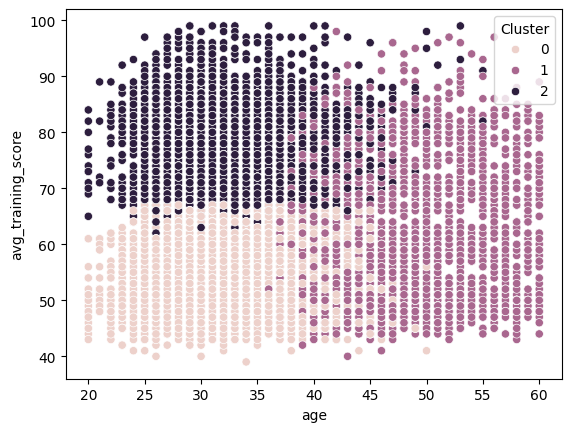

In [ ]:
sns.scatterplot(data=df, x="age", y="avg_training_score", hue="Cluster")
plt.show()

In [ ]:
df.groupby("Cluster")[[
    "age",
    "no_of_trainings",
    "previous_year_rating",
    "length_of_service",
    "avg_training_score"
]].mean().round(2)

,age,no_of_trainings,previous_year_rating,length_of_service,avg_training_score
Cluster,,,,,
0,32.09,1.22,3.29,4.43,53.85
1,46.63,1.14,3.46,11.69,61.38
2,32.20,1.36,3.36,4.52,79.12


Feature Importance

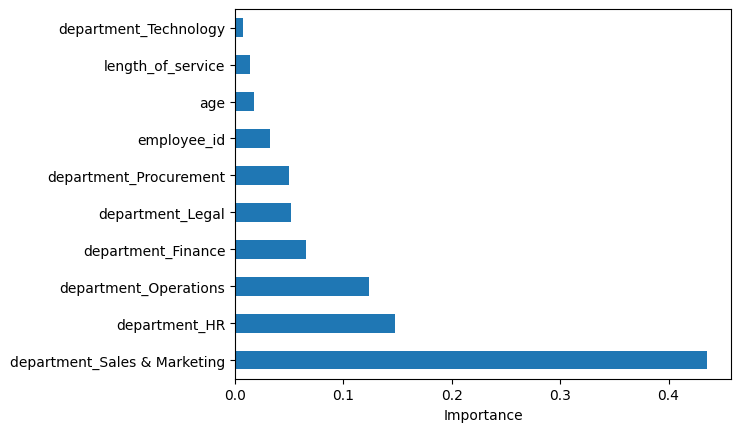

In [ ]:
importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

importance.head(10).plot(kind='barh')
plt.xlabel("Importance")
plt.show()

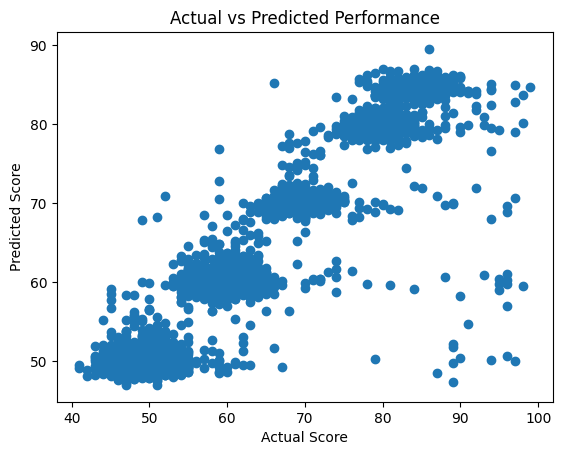

In [ ]:
plt.scatter(y_test, y_pred)
plt.xlabel("Actual Score")
plt.ylabel("Predicted Score")
plt.title("Actual vs Predicted Performance")
plt.show()

In [ ]:
print("Random Forest Results")
print("MAE:", round(mean_absolute_error(y_test, y_pred), 2))
print("R² Score:", round(r2_score(y_test, y_pred), 2))

print("\nEmployee Clusters:")
print(df["Cluster"].value_counts().sort_index())

Random Forest Results
MAE: 2.88
R² Score: 0.88

Employee Clusters:
Cluster
0    8730
1    3215
2    5470
Name: count, dtype: int64


In [ ]:
cluster_profile = df.groupby("Cluster")[
    ["age", "no_of_trainings", "previous_year_rating",
     "length_of_service", "avg_training_score"]
].mean().round(2)

cluster_profile

,age,no_of_trainings,previous_year_rating,length_of_service,avg_training_score
Cluster,,,,,
0,32.09,1.22,3.29,4.43,53.85
1,46.63,1.14,3.46,11.69,61.38
2,32.20,1.36,3.36,4.52,79.12
